In [ ]:
%load_ext autoreload
%autoreload 2

import json
import os
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

from entrained_gamma import *

PATH_TO_DATA = Path('data/DeIdentifiedForAashish')

plt.style.use('seaborn-v0_8-whitegrid')
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['figure.figsize'] = (16, 9)
mpl.rcParams['font.family'] = 'Arial'

# Entrained gamma, deidentified data

In [3]:
# LOAD JSONS
files = sorted(PATH_TO_DATA.rglob("*.json"))
stems = pd.Series([p.stem for p in files], name="stem")

recs = []
for path in tqdm(files):
    skipped = 0
    with open(path, "r") as f:
        try:
            recs.append(json.load(f))
        except json.decoder.JSONDecodeError:
            continue
print(f"{len(recs)}/{len(files)} files loaded successfully.")
master_df = pd.DataFrame(recs)

100%|██████████| 280/280 [00:01<00:00, 206.47it/s]

175/280 files loaded successfully.


In [4]:
df = master_df.copy()
df.insert(0, 'patient', '')
df.insert(1, 'visit', '')
df.insert(2, 'diagnosis', pd.json_normalize(master_df.PatientInformation)['Initial.Diagnosis'])
df[['patient', 'visit']] = stems.str.split('_', expand=True)
df = df.filter(regex='patient|visit|diag|^Session|^Groups$|^Brain')
df = df.join(
    pd.json_normalize(
        master_df.DiagnosticData.map(lambda x: x if isinstance(x, dict) else {}),
        max_level=1,
    ).add_prefix("DiagnosticData.")
)
df[['SessionDate', 'SessionEndDate']] = df[['SessionDate', 'SessionEndDate']].apply(pd.to_datetime)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 23 columns):
 #   Column                                                                Non-Null Count  Dtype              
---  ------                                                                --------------  -----              
 0   patient                                                               175 non-null    str                
 1   visit                                                                 175 non-null    str                
 2   diagnosis                                                             175 non-null    str                
 3   SessionDate                                                           175 non-null    datetime64[us, UTC]
 4   SessionEndDate                                                        157 non-null    datetime64[us, UTC]
 5   Groups                                                                175 non-null    object             
 6   BrainSenseSur

In [5]:
df.diagnosis.value_counts()

diagnosis
DiagnosisTypeDef.ParkinsonsDisease    152
DiagnosisTypeDef.Dystonia              13
DiagnosisTypeDef.EssentialTremor        7
DiagnosisTypeDef.Other                  2
DiagnosisTypeDef.Default                1
Name: count, dtype: int64

### BrainSenseLfp

In [6]:
blfp = df[["patient", "visit", "SessionDate", "BrainSenseLfp"]].copy()

blfp = blfp.dropna()
blfp.BrainSenseLfp = blfp.BrainSenseLfp.map(lambda x: x if isinstance(x, list) else [x])
blfp = blfp.explode("BrainSenseLfp").reset_index(drop=True)
norm = pd.json_normalize(blfp.BrainSenseLfp, max_level=0)
blfp = pd.concat([blfp.drop(columns="BrainSenseLfp"), norm], axis=1)

blfp["FirstPacketDateTime"] = blfp.FirstPacketDateTime.map(pd.to_datetime)
blfp.Channel = blfp.Channel.str.split(",")
blfp = blfp.explode("Channel").reset_index(drop=True)

# extract hemisphere from channel name
hemisphere = blfp.Channel.str.extract(r"_(LEFT|RIGHT)$", expand=False).map(
    {"LEFT": "Left", "RIGHT": "Right"}
)
params = pd.Series([d.get(k) for d, k in zip(blfp.TherapySnapshot, hemisphere)])

PARAM_COLS = [
    "StreamingAdaptiveMode",
    "AdaptiveTherapyStatus",
    "PulseWidthInMicroSecond",
    "RateInHertz",
    "LowerLimitInMilliAmps",
    "UpperLimitInMilliAmps",
    "FrequencyInHertz",
]

blfp = pd.concat([blfp, pd.json_normalize(params, max_level=0)[PARAM_COLS]], axis=1)
lfp_data = [pd.json_normalize(x, max_level=0) for x in blfp.LfpData]
blfp['stim_time_ms'] = [df.TicksInMs.to_numpy() for df in lfp_data]
blfp['GlobalSequences'] = [df.Seq.unique() for df in lfp_data]

settings = [pd.json_normalize(df[h]) for df, h in zip(lfp_data, hemisphere)]
blfp['stim_mA'] = [df.mA.to_numpy() for df in settings]
blfp['LFP'] = [df.LFP.to_numpy() for df in settings]
blfp = blfp.drop(columns=["LfpData", "TherapySnapshot"])

blfp.info()

<class 'pandas.DataFrame'>
RangeIndex: 358 entries, 0 to 357
Data columns (total 19 columns):
 #   Column                              Non-Null Count  Dtype              
---  ------                              --------------  -----              
 0   patient                             358 non-null    str                
 1   visit                               358 non-null    str                
 2   SessionDate                         358 non-null    datetime64[us, UTC]
 3   Channel                             358 non-null    str                
 4   FirstPacketDateTime                 358 non-null    datetime64[us, UTC]
 5   FirstPacketDateTimeBlockId          240 non-null    float64            
 6   FirstPacketDateTimeOffsetInSeconds  240 non-null    float64            
 7   SampleRateInHz                      358 non-null    int64              
 8   StreamingAdaptiveMode               240 non-null    str                
 9   AdaptiveTherapyStatus               240 non-null    st

In [7]:
blfp.iloc[0]

patient                                                                           SUB01
visit                                                                                01
SessionDate                                                   2026-03-03 15:20:19+00:00
Channel                                                                   ZERO_TWO_LEFT
FirstPacketDateTime                                           2026-03-03 15:36:22+00:00
FirstPacketDateTimeBlockId                                                         34.0
FirstPacketDateTimeOffsetInSeconds                                               3819.0
SampleRateInHz                                                                        2
StreamingAdaptiveMode                                  StreamingAdaptiveModeDef.PASSIVE
AdaptiveTherapyStatus                                      ADBSStatusDef.NOT_CONFIGURED
PulseWidthInMicroSecond                                                              60
RateInHertz                     

### BrainSenseTimeDomain

In [8]:
bstd = df[["patient", "visit", "diagnosis", "SessionDate", "BrainSenseTimeDomain"]].copy()

# The BSTD column is originally lists of samples per patient, explode+normalize to get one sample per row
bstd = bstd.dropna()
bstd.BrainSenseTimeDomain = bstd.BrainSenseTimeDomain.map(lambda x: x if isinstance(x, list) else [x])
bstd = bstd.explode("BrainSenseTimeDomain").reset_index(drop=True)
norm = pd.json_normalize(bstd.BrainSenseTimeDomain)
bstd = pd.concat([bstd.drop(columns="BrainSenseTimeDomain"), norm], axis=1)

# Parse string data into their appropriate types
bstd.TimeDomainData = bstd.TimeDomainData.map(np.array)
bstd["FirstPacketDateTime"] = pd.to_datetime(bstd.FirstPacketDateTime)
LIST_FIELDS = ["GlobalSequences", "GlobalPacketSizes", "TicksInMses"]
bstd[LIST_FIELDS] = bstd[LIST_FIELDS].map(
    lambda s: [
        int(i) for i in s.split(",") if i.isnumeric()
    ]  # convert comma-separated strings to lists of integers
)

# Check for weird length mismatches and drop those samples
for sample in bstd.itertuples():
    if sum(sample.GlobalPacketSizes) != len(sample.TimeDomainData):
        print(
            f"Recording sample {sample.Index} (from {sample.patient}_{sample.visit} "
            f"channel {sample.Channel}) has inconsistent lengths, dropping."
        )
        bstd = bstd.drop(sample.Index)

# Use method from user guide to get time vector for each sample
bstd["time_ms"] = bstd.apply(get_time_BSTD, axis=1)

# Filter to only include samples with duration > 3 seconds
# to make tolerance of 2 seconds in merge_asof safe
dur_s = (bstd.time_ms.str[-1] - bstd.time_ms.str[0])/1000 + 1/bstd.SampleRateInHz
bstd = bstd[dur_s > 3]

# JOIN IN BLFP TO GET SETTINGS
left = bstd.sort_values("FirstPacketDateTime")
right = blfp.sort_values("FirstPacketDateTime")
JOIN_COLS = [ # columns in blfp to keep for join
    "patient",
    "visit",
    "Channel",
    "FirstPacketDateTime",
    "stim_mA",
    "stim_time_ms",
    "LFP",
] + PARAM_COLS

bstd = pd.merge_asof(
    left,
    right[JOIN_COLS],
    on="FirstPacketDateTime",
    by=["patient", "visit", "Channel"],
    direction="nearest",
    tolerance=pd.Timedelta("2s"),
)
bstd = bstd.sort_values(
    ["patient", "visit", "Channel", "FirstPacketDateTime"]
).reset_index(drop=True)

# Separate out discontinuous segments into separate rows
bstd = bstd.reset_index(names='original_sample')
bstd = pd.concat(bstd.apply(separate_disconts, axis=1).to_list(), ignore_index=True)

# Get duration of each separated sample in seconds
bstd['duration_s'] = (bstd.time_ms.str[-1] - bstd.time_ms.str[0])/1000 + 1/bstd.SampleRateInHz

# Make sure the duration makes sense with packet sizes
assert np.all(
    np.abs(bstd.GlobalPacketSizes.map(sum) / bstd.SampleRateInHz / bstd.duration_s - 1)
    < 1e-3
), (
    "duration_s should be equal to the sum of GlobalPacketSizes divided by SampleRateInHz"
)

bstd.info()

<class 'pandas.DataFrame'>
RangeIndex: 548 entries, 0 to 547
Data columns (total 28 columns):
 #   Column                              Non-Null Count  Dtype              
---  ------                              --------------  -----              
 0   original_sample                     548 non-null    int64              
 1   patient                             548 non-null    str                
 2   visit                               548 non-null    str                
 3   diagnosis                           548 non-null    str                
 4   SessionDate                         548 non-null    datetime64[us, UTC]
 5   Pass                                548 non-null    str                
 6   GlobalSequences                     548 non-null    object             
 7   GlobalPacketSizes                   548 non-null    object             
 8   TicksInMses                         548 non-null    object             
 9   Channel                             548 non-null    st

In [9]:
bstd.iloc[76]

original_sample                                                                      59
patient                                                                           SUB05
visit                                                                                01
diagnosis                                            DiagnosisTypeDef.ParkinsonsDisease
SessionDate                                                   2025-11-18 13:41:43+00:00
Pass                                                                                   
GlobalSequences                       [5604, 5605, 5606, 5607, 5609, 5610, 5611, 561...
GlobalPacketSizes                     [63, 62, 63, 62, 63, 62, 63, 62, 63, 62, 63, 6...
TicksInMses                           [4439600, 4439850, 4440100, 4440350, 4440600, ...
Channel                                                                 ONE_THREE_RIGHT
Gain                                                                                228
FirstPacketDateTime             

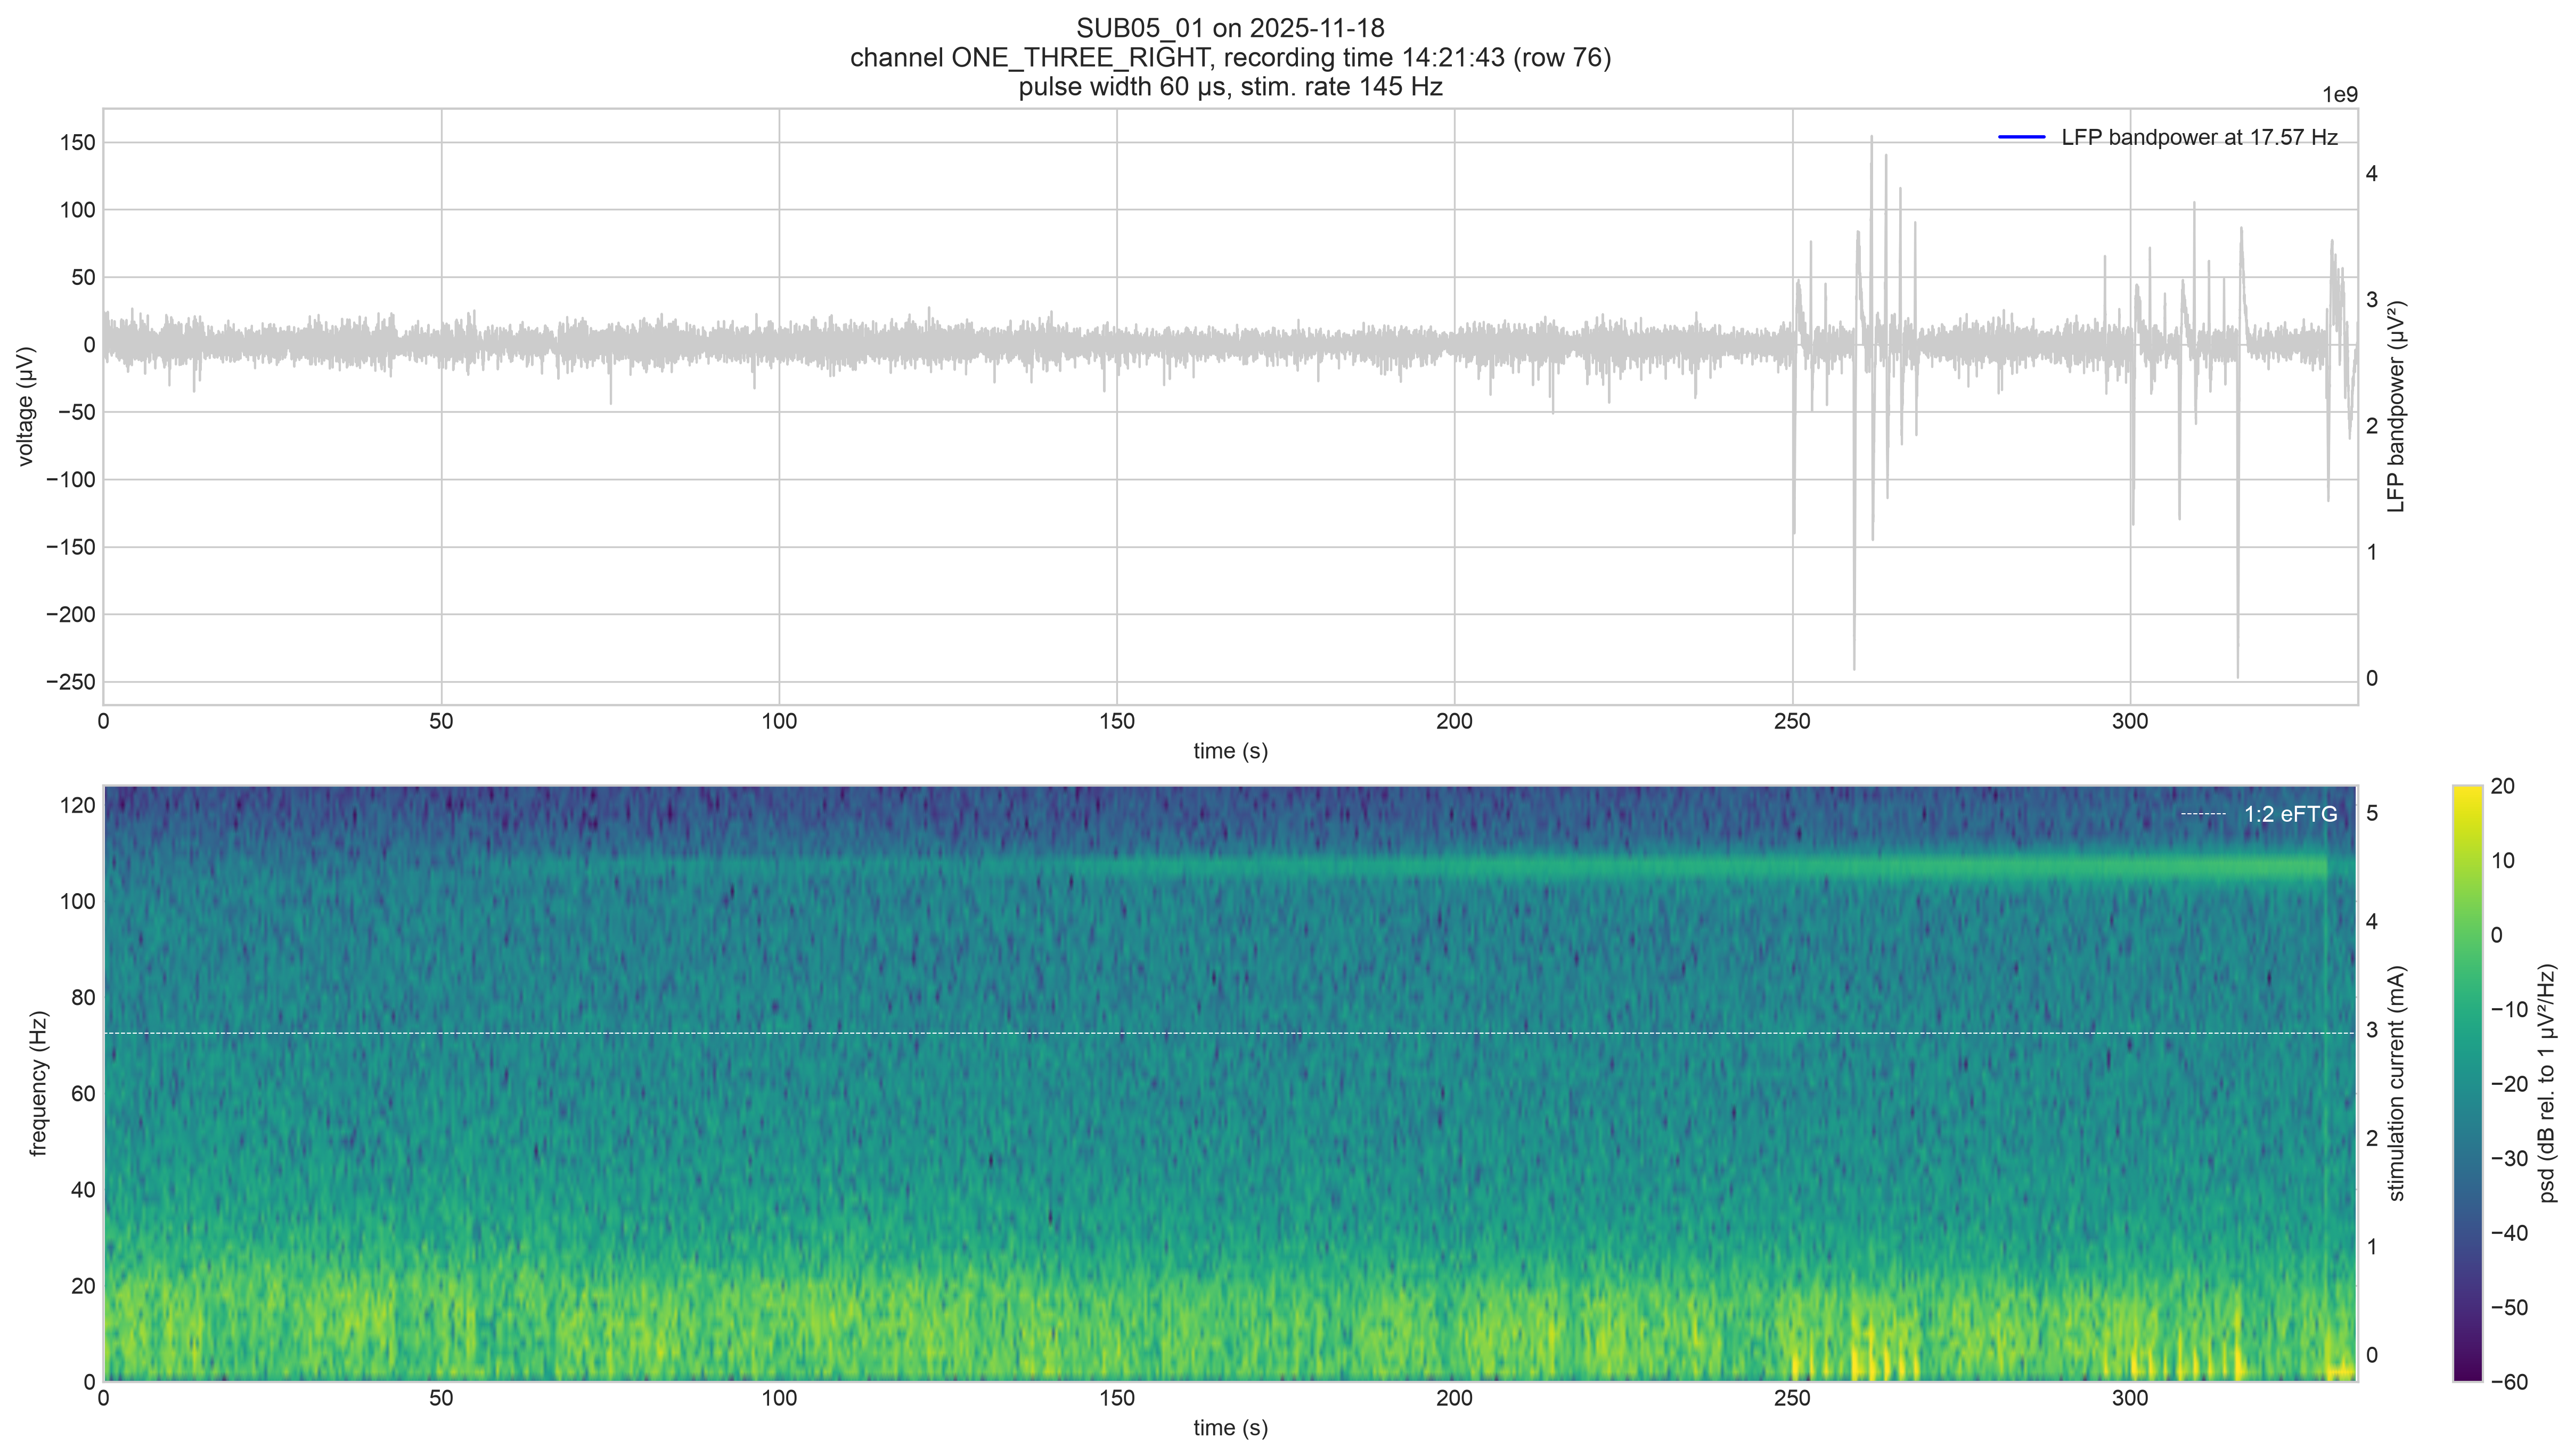

In [10]:
plot_sample(bstd.iloc[76])

In [ ]:
# DIRECTORY = "figures/deid_data/BrainSenseTimeDomain"
# os.makedirs(DIRECTORY, exist_ok=True)

# bstd.drop(columns='original_sample').to_csv(f"{DIRECTORY}/recordings.csv", index_label='row')

# mask = (bstd.duration_s > 60) & (bstd.diagnosis == 'DiagnosisTypeDef.ParkinsonsDisease')
# bstd_filt = bstd[mask].reset_index(names='name')

# for sample in tqdm(bstd_filt.itertuples(), total=len(bstd_filt), desc="plotting"):
#     plot_sample(sample)
#     plt.savefig(
#         f"{DIRECTORY}/{sample.patient}_{sample.visit}-ch{sample.Channel}-row{sample.name}.png",
#         pad_inches="layout",
#     )
#     plt.close()
